In [ ]:
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import os, psutil
import numpy as np
import sys
import subprocess

# Matplotlib imports
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import AutoLocator, MaxNLocator, AutoMinorLocator

# Scipy imports
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator

# Iris imports
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole

from pathlib import Path
sys.path.append("/Users/amritrajdash/programming/TEAMx/amrit_exploration/")
import momentum_fluxes.momentum_flux_funcs as tx

orog_data_path_base = "/Users/amritrajdash/programming/TEAMx/amrit_exploration/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
#original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

sonde_ids = []

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = "/Users/amritrajdash/programming/TEAMx/amrit_exploration//momentum_fluxes/iop_17_18/" 

raw_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_raw_sonde_data").glob("*.nc"))
coarse_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_coarse_sonde_data").glob("*.nc"))
model_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_model_sonde_data").glob("*.nc"))

index = 3

# %%
# Paths for the sonde and model data

sonde_id = raw_sonde_list[index].stem[13:21]

raw_data_path = raw_sonde_list[index]
coarse_data_path = coarse_sonde_list[index]
model_data_path = model_sonde_list[index]

data_path_orog = "orography_u-eb392_run1_0p3km.nc"

#original_model_data_path_4 = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

mem = psutil.Process(os.getpid()).memory_info().rss / 1024**3
print(f"Current RAM usage: {mem:.2f} GB")


Current RAM usage: 0.19 GB


PosixPath('/Users/amritrajdash/programming/TEAMx/amrit_exploration/momentum_fluxes/iop_17_18/iop_17_18_raw_sonde_data/202502251100_S0240214_STERZING_NCAS_v2.0.TPB.nc')

In [3]:
# %%
# Import in some data to see what it looks like
plot_title_affix = f"{sonde_id}"
cubelist_s_path = f"{coarse_data_path}"
cubelist_m_path = f"{model_data_path}"
cubelist_r_path = f"{raw_data_path}"

#cubelist_mo_path = f"{original_model_data_path}"
orog_cube_path = f"{data_path_base}/{data_path_orog}"

cubelist_s = iris.load(cubelist_s_path)
cubelist_m = iris.load(cubelist_m_path)
#cubelist_mo = iris.load(cubelist_mo_path)
orog_cube = iris.load(orog_cube_path)

coarse_flux_list = sorted(Path(f"{data_path_base}/iop_17_18_coarse_sonde_flux_arrays").glob("*.npz"))
model_flux_list = sorted(Path(f"{data_path_base}/iop_17_18_model_sonde_flux_arrays").glob("*.npz"))


cubelist_s

Range Of Radiosonde From Launch Site (m),time
Shape,5676
Dimension coordinates,
time,x
Attributes,
Conventions,'CF-1.13'
acknowledgement,"'Original Level 2 data provided by NCAS, UK'"
averaging_interval,'1 s'
contact,"'T. P. Banyard, tpb38@bath.ac.uk'"
date_created,'2026-09-14 13:10:13 UTC'
deployment_mode,'land'


In [4]:
alts_list = []
Flux_u_s_list = []
Flux_v_s_list = []
u_s_means_list = []
v_s_means_list = []
u_s_raw_list = []
v_s_raw_list = []

Flux_u_m_list = []
Flux_v_m_list = []
u_m_means_list = []
v_m_means_list = []
u_m_raw_list = []
v_m_raw_list = []

sonde_title_labels = []


for i in range(0, len(coarse_flux_list)):
    alt_nonans, alt_mask = tx.nonans_cubedata(coarse_sonde_list[i], "altitude")

    u_s_wind_nonans, u_s_wind_mask = tx.nonans_cubedata(coarse_sonde_list[i], "eastward_wind")
    u_s_wind_prime, u_s_wind_mean, u_s_wind_coeffs = tx.get_means_primes_pfit(u_s_wind_nonans, alt_nonans, p_deg=4)

    v_s_wind_nonans, v_s_wind_mask = tx.nonans_cubedata(coarse_sonde_list[i], "northward_wind")
    v_s_wind_prime, v_s_wind_mean, v_s_wind_coeffs = tx.get_means_primes_pfit(v_s_wind_nonans, alt_nonans, p_deg=4)

    u_m_wind_nonans, u_m_wind_mask = tx.nonans_cubedata(coarse_sonde_list[i], "eastward_wind")
    u_m_wind_prime, u_m_wind_mean, u_m_wind_coeffs = tx.get_means_primes_pfit(u_m_wind_nonans, alt_nonans, p_deg=4)

    v_m_wind_nonans, v_m_wind_mask = tx.nonans_cubedata(coarse_sonde_list[i], "northward_wind")
    v_m_wind_prime, v_m_wind_mean, v_m_wind_coeffs = tx.get_means_primes_pfit(v_m_wind_nonans, alt_nonans, p_deg=4)

    Flux_u_s = tx.flux_from_sonde(cubelist_path=coarse_sonde_list[i], component="zonal")
    Flux_v_s = tx.flux_from_sonde(cubelist_path=coarse_sonde_list[i], component="meridional")

    Flux_u_m = tx.flux_from_sonde(cubelist_path=model_sonde_list[i], component="zonal")
    Flux_v_m = tx.flux_from_sonde(cubelist_path=model_sonde_list[i], component="meridional") 

    name = coarse_flux_list[i].stem
    id = name[13:21]
    sonde_title_labels.append(id)

    alts_list.append(1e-3*alt_nonans)
    Flux_u_s_list.append(Flux_u_s)
    Flux_v_s_list.append(Flux_v_s)
    u_s_means_list.append(u_s_wind_mean)
    v_s_means_list.append(v_s_wind_mean)
    u_s_raw_list.append(u_s_wind_nonans)
    v_s_raw_list.append(v_s_wind_nonans)

    Flux_u_m_list.append(Flux_u_m)
    Flux_v_m_list.append(Flux_v_m)
    u_m_means_list.append(u_m_wind_mean)
    v_m_means_list.append(v_m_wind_mean)
    u_m_raw_list.append(u_m_wind_nonans)
    v_m_raw_list.append(v_m_wind_nonans)




    
    

Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (3712,)
Brunt Vaisala Frequency Calculated
Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (3712,)
Brunt Vaisala Frequency Calculated


/Users/amritrajdash/miniconda3/envs/lare3d/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (3712,)
Brunt Vaisala Frequency Calculated
Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (3712,)
Brunt Vaisala Frequency Calculated
Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (5270,)
Brunt Vaisala Frequency Calculated
Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (5270,)
Brunt Vaisala Frequency Calculated
Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed Normalised Temperature
Shape of transformed temperature: (5270,)
Brunt Vaisala Frequency Calculated
Means and Perturbations for Wind, Temperature, Pressure found.
Hilbert Transformed No

In [5]:
# This is the minimum number of samples from all the sondes in the lists above
# All other sondes will get sampled accordingly
median_len = int(np.max([len(i) for i in alts_list]))
max_alt_idx = np.argmax([np.nanmax(i) for i in alts_list])

indices_list = []
for i in alts_list:
    indices_list.append(np.linspace(0, len(i)-1 , median_len, dtype=int))

sampled_alts_list = []

sampled_flux_u_s_list = []
sampled_flux_v_s_list = []
sampled_u_s_means_list = []
sampled_v_s_means_list = []
sampled_u_s_raw_list = []
sampled_v_s_raw_list = []

sampled_flux_u_m_list = []
sampled_flux_v_m_list = []
sampled_u_m_means_list = []
sampled_v_m_means_list = []
sampled_u_m_raw_list = []
sampled_v_m_raw_list = []


for i,j in enumerate(alts_list):    
    sampled_alts_list.append(alts_list[i][indices_list[i]])

    sampled_flux_u_s_list.append(Flux_u_s_list[i][indices_list[i]])
    sampled_flux_v_s_list.append(Flux_v_s_list[i][indices_list[i]])
    sampled_u_s_means_list.append(u_s_means_list[i][indices_list[i]])
    sampled_v_s_means_list.append(v_s_means_list[i][indices_list[i]])
    sampled_u_s_raw_list.append(u_s_raw_list[i][indices_list[i]])
    sampled_v_s_raw_list.append(v_s_raw_list[i][indices_list[i]])

    sampled_flux_u_m_list.append(Flux_u_m_list[i][indices_list[i]])
    sampled_flux_v_m_list.append(Flux_v_m_list[i][indices_list[i]])
    sampled_u_m_means_list.append(u_m_means_list[i][indices_list[i]])
    sampled_v_m_means_list.append(v_m_means_list[i][indices_list[i]])
    sampled_u_m_raw_list.append(u_m_raw_list[i][indices_list[i]])
    sampled_v_m_raw_list.append(v_m_raw_list[i][indices_list[i]]) 



In [6]:
# Calculate the dot product between the flux vector and hoz wind vector

sampled_f_u_dot_s_list = []
sampled_f_u_dot_m_list = []
sampled_flux_mag_m_list = []
sampled_flux_mag_s_list = []

for i in range(0, len(Flux_u_m_list)):
    f_u_dot_s = tx.flux_wind_dot(f_u = sampled_flux_u_s_list[i], f_v=sampled_flux_v_s_list[i], u=sampled_u_s_means_list[i], v=sampled_v_s_means_list[i])
    f_u_dot_m = tx.flux_wind_dot(f_u = sampled_flux_u_m_list[i], f_v=sampled_flux_v_m_list[i], u=sampled_u_m_means_list[i], v=sampled_v_m_means_list[i])

    sampled_f_u_dot_s_list.append(f_u_dot_s)
    sampled_f_u_dot_m_list.append(f_u_dot_m)

    # Calculate the magnitude
    sampled_flux_mag_s = np.hypot(sampled_flux_u_s_list[i], sampled_flux_v_s_list[i])
    sampled_flux_mag_m = np.hypot(sampled_flux_u_m_list[i], sampled_flux_v_m_list[i])

    sampled_flux_mag_s_list.append(sampled_flux_mag_s)
    sampled_flux_mag_m_list.append(sampled_flux_mag_m)

In [7]:
print(np.ndim(sampled_flux_mag_s[0]))
print(np.ndim(sampled_alts_list[0]))

0
1


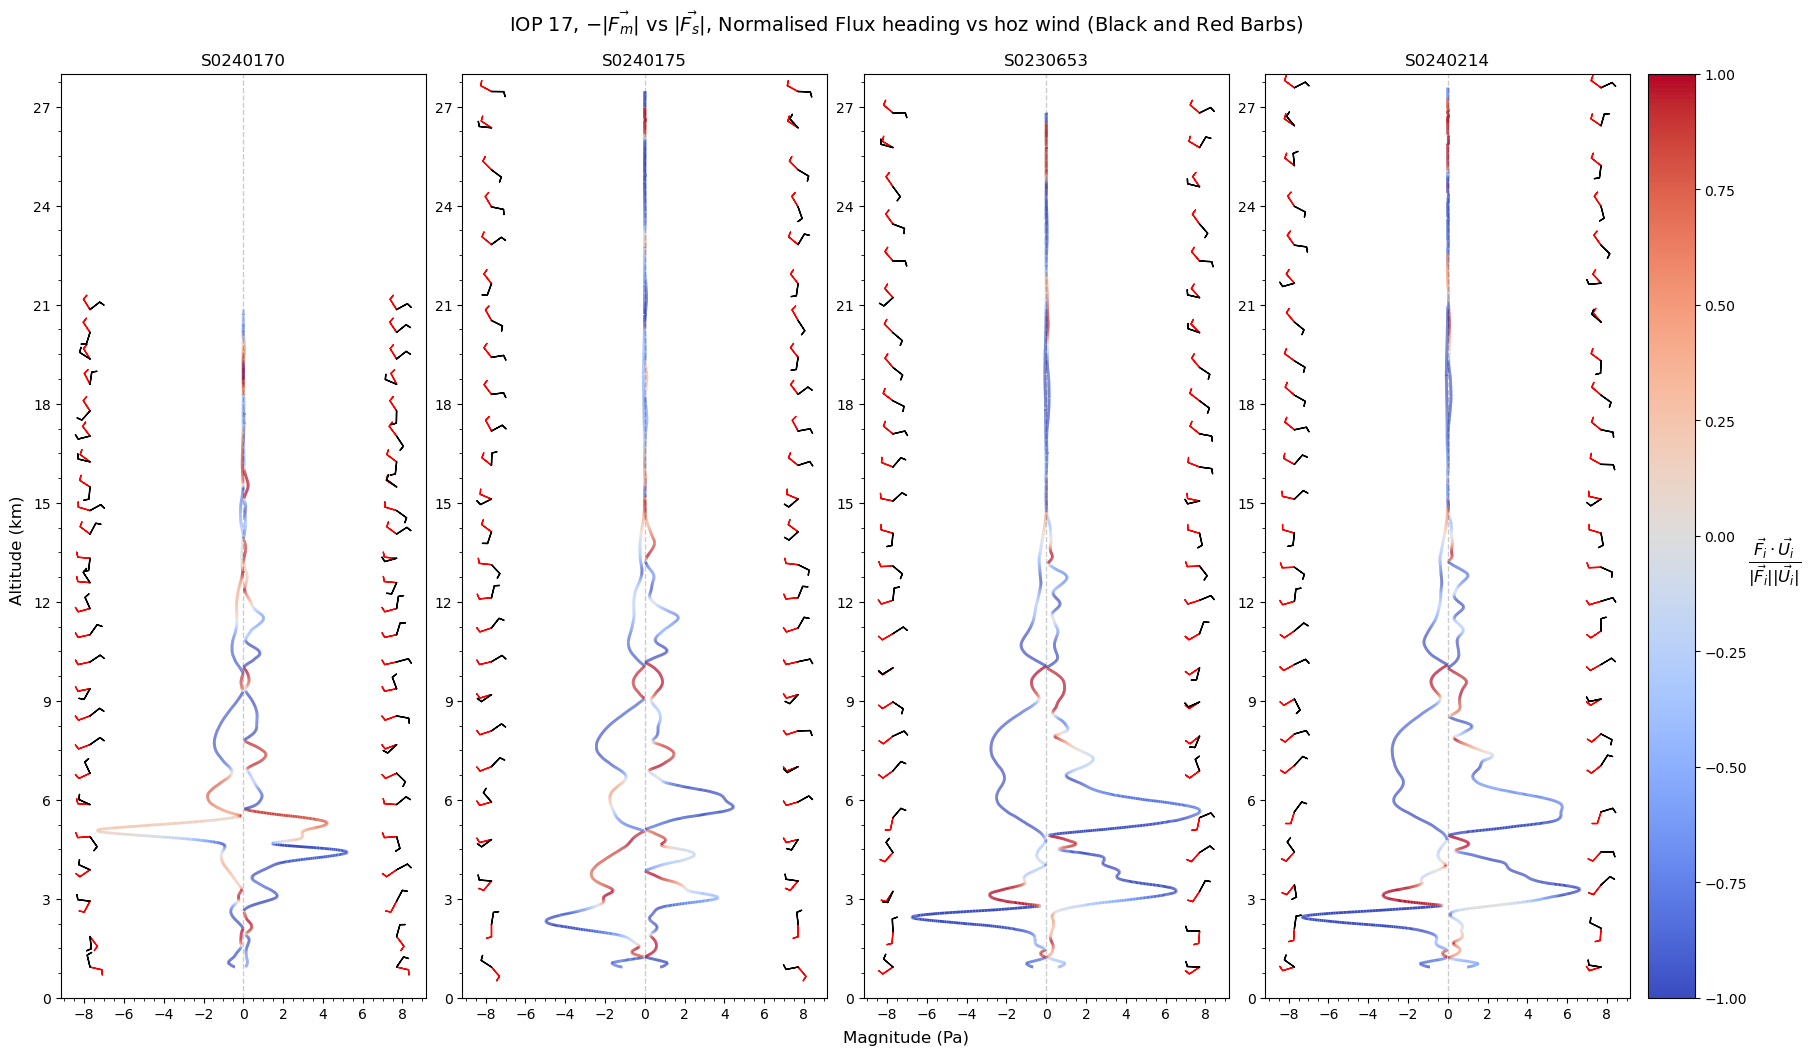

In [ ]:
# create function for plot 3
# take in fig, ax, create the plot

fig = plt.figure(figsize=(18,10), layout="constrained")

axis = fig.subplots(1,4, sharey=True, sharex=True)

wind_arrays = [[[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]],
               [[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]],
               [[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]],
               [[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]]]

Flux_arrays = [[[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]],
               [[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]],
               [[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]],
               [[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]]]

wind_arrays = [[[sampled_u_m_raw_list[i],sampled_v_m_raw_list[i]], [sampled_u_s_raw_list[i],sampled_v_s_raw_list[i]]] for i in range(0, len(sampled_u_s_raw_list))]
Flux_arrays = [[[sampled_flux_u_m_list[i],sampled_flux_v_m_list[i]], [sampled_flux_u_s_list[i],sampled_flux_v_s_list[i]]] for i in range(0, len(sampled_flux_u_s_list))]


speed_norm_mag = 10
barb_length = 4.2
barb_count = 25
left_pos = 0.08
right_pos = 0.92

for j, i in enumerate(axis):
    i = tx.return_barbs(i, u_array=wind_arrays[j][0][0], v_array=wind_arrays[j][0][1],
                     alt_array=sampled_alts_list[j], color="red", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=left_pos)
    
    i = tx.return_barbs(i, u_array=Flux_arrays[j][0][0], v_array=Flux_arrays[j][0][1],
                     alt_array=sampled_alts_list[j], color="black", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=left_pos)
    
    i = tx.return_barbs(i, u_array=wind_arrays[j][1][0], v_array=wind_arrays[j][1][1],
                     alt_array=sampled_alts_list[j], color="red", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=right_pos)
    
    i = tx.return_barbs(i, u_array=Flux_arrays[j][1][0], v_array=Flux_arrays[j][1][1],
                     alt_array=sampled_alts_list[j], color="black", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=right_pos)
    

for i, ax in enumerate(axis):
    ax, lc = tx.add_profile_to_ax(ax, 
                                  alt_km=sampled_alts_list[i],
                                  F_mag_s=sampled_flux_mag_s_list[i], 
                                  F_mag_m=sampled_flux_mag_m_list[i],
                                  f_u_dot_m=sampled_f_u_dot_m_list[i],
                                  f_u_dot_s=sampled_f_u_dot_s_list[i], title = sonde_title_labels[i])

    ax.tick_params(axis="y", labelleft=True)
    ax.set_ylim(0, 28)


# Set cbar and cbar label
cbar_m = fig.colorbar(mappable=lc, ax=axis[3])
cbar_m.set_label(r"$\frac{\vec{F_i} \cdot \vec{U_i}}{|\vec{F_i}| |\vec{U_i}|}$", labelpad=20,rotation=0, fontsize=17)

# Set figure title and ax params
fig.suptitle(r"IOP 17, $-|\vec{F_m}|$ vs $|\vec{F_s}|$, Normalised Flux heading vs hoz wind (Black and Red Barbs)", fontsize=14, y=1.04)
fig.supylabel("Altitude (km)")
fig.supxlabel("Magnitude (Pa)")

plt.show()
#fig.savefig("Flux_magnitude_and_direction_iop_17_dpi600.png", dpi=600, bbox_inches="tight")

(5676,)


Text(0.5, 1.0, 'Meridional Flux')

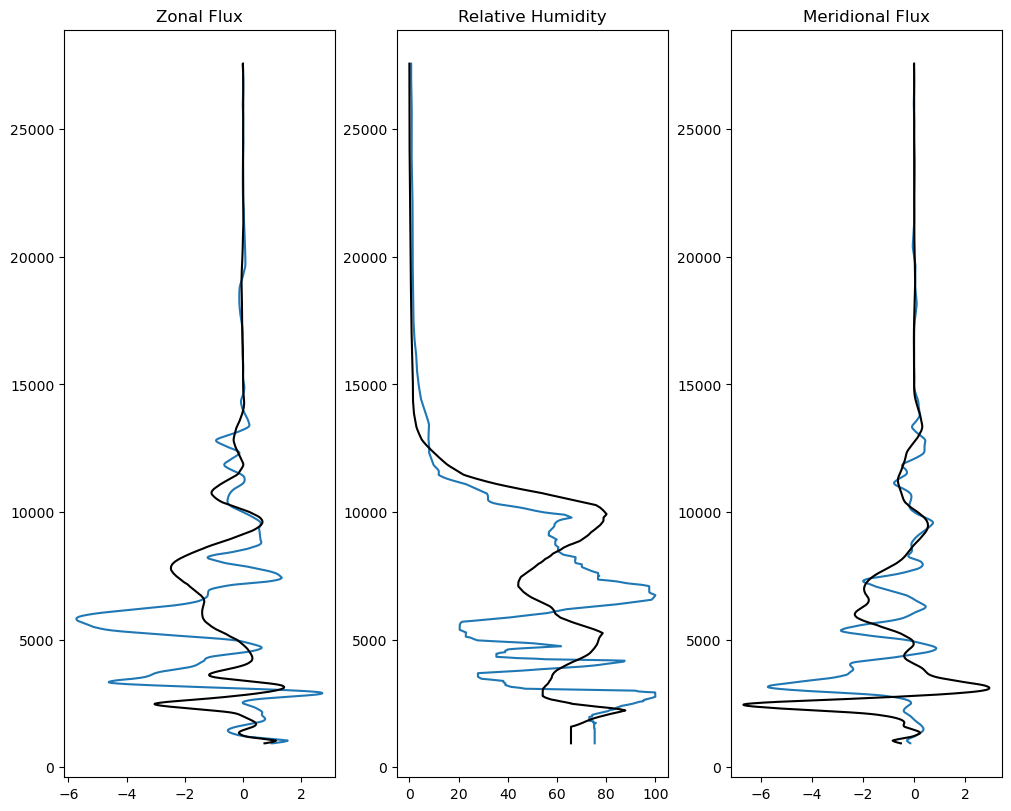

In [24]:
# Here, try to plot a profile of relative humidity

rh_s_nonans, mask_0 = tx.nonans_cubedata(cubelist_s_path, "relative_humidity")
alt_s_nonans,  mask_3 = tx.nonans_cubedata(cubelist_s_path, "altitude")
alt_m_nonans, mask_1 = tx.nonans_cubedata(cubelist_m_path, "altitude")
rh_m_nonans, mask_2 = tx.nonans_cubedata(cubelist_m_path, "relative_humidity")

F_u_m, F_v_m = Flux_arrays[index][0]
F_u_s, F_v_s = Flux_arrays[index][1]

fig = plt.figure(figsize=(10, 8), layout="constrained")
ax = fig.subplots(1,3)


print(np.shape(rh_s_nonans))

ax[0].plot(F_u_s, alt_s_nonans)
ax[0].plot(F_u_m, alt_s_nonans, color="k")
ax[0].set_title("Zonal Flux")

ax[1].plot(rh_s_nonans, alt_s_nonans)
ax[1].plot(rh_m_nonans, alt_s_nonans, color="k")
ax[1].set_title("Relative Humidity")

ax[2].plot(F_v_s, alt_s_nonans)
ax[2].plot(F_v_m, alt_s_nonans, color="k")
ax[2].set_title("Meridional Flux")




In [ ]:
# create function for plot 3
# take in fig, ax, create the plot

fig = plt.figure(figsize=(18,10), layout="constrained")

axis = fig.subplots(1,4, sharey=True, sharex=True)

wind_arrays = [[[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]],
               [[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]],
               [[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]],
               [[u_m_wind_nonans, v_m_wind_nonans], [u_s_wind_nonans, v_s_wind_nonans]]]

Flux_arrays = [[[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]],
               [[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]],
               [[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]],
               [[Flux_u_m, Flux_v_m], [Flux_u_s, Flux_v_s]]]

wind_arrays = [[[sampled_u_m_raw_list[i],sampled_v_m_raw_list[i]], [sampled_u_s_raw_list[i],sampled_v_s_raw_list[i]]] for i in range(0, len(sampled_u_s_raw_list))]
Flux_arrays = [[[sampled_flux_u_m_list[i],sampled_flux_v_m_list[i]], [sampled_flux_u_s_list[i],sampled_flux_v_s_list[i]]] for i in range(0, len(sampled_flux_u_s_list))]


speed_norm_mag = 10
barb_length = 4.2
barb_count = 25
left_pos = 0.08
right_pos = 0.92

for j, i in enumerate(axis):
    i = tx.return_barbs(i, u_array=wind_arrays[j][0][0], v_array=wind_arrays[j][0][1],
                     alt_array=sampled_alts_list[j], color="red", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=left_pos)
    
    i = tx.return_barbs(i, u_array=Flux_arrays[j][0][0], v_array=Flux_arrays[j][0][1],
                     alt_array=sampled_alts_list[j], color="black", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=left_pos)
    
    i = tx.return_barbs(i, u_array=wind_arrays[j][1][0], v_array=wind_arrays[j][1][1],
                     alt_array=sampled_alts_list[j], color="red", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=right_pos)
    
    i = tx.return_barbs(i, u_array=Flux_arrays[j][1][0], v_array=Flux_arrays[j][1][1],
                     alt_array=sampled_alts_list[j], color="black", norm_mag=speed_norm_mag, 
                     barb_length=barb_length, barb_count=barb_count, position=right_pos)
    

for i, ax in enumerate(axis):
    ax, lc = tx.add_profile_to_ax(ax, 
                                  alt_km=sampled_alts_list[i],
                                  F_mag_s=sampled_flux_mag_s_list[i], 
                                  F_mag_m=sampled_flux_mag_m_list[i],
                                  f_u_dot_m=sampled_f_u_dot_m_list[i],
                                  f_u_dot_s=sampled_f_u_dot_s_list[i], title = sonde_title_labels[i])

    ax.tick_params(axis="y", labelleft=True)
    ax.set_ylim(0, 28)


# Set cbar and cbar label
cbar_m = fig.colorbar(mappable=lc, ax=axis[3])
cbar_m.set_label(r"$\frac{\vec{F_i} \cdot \vec{U_i}}{|\vec{F_i}| |\vec{U_i}|}$", labelpad=20,rotation=0, fontsize=17)

# Set figure title and ax params
fig.suptitle(r"IOP 17, $-|\vec{F_m}|$ vs $|\vec{F_s}|$, Normalised Flux heading vs hoz wind (Black and Red Barbs)", fontsize=14, y=1.04)
fig.supylabel("Altitude (km)")
fig.supxlabel("Magnitude (Pa)")

plt.show()


# IDEA: INSTEAD OF HAVING WIND DIRECTION SHOWING UP AS COLOUR, HAVE THE RELATIVE HUMIDITY ON 
# THERE INSTEAD. THIS WOULD ALLOW COMPARING THE TWO